In [1]:
# CELL 1: Install dependencies
!pip install torch transformers pandas numpy scikit-learn matplotlib seaborn nltk plotly --quiet

import os
import gc
import random
import pickle
import pandas as pd
import numpy as np

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import BertTokenizer, BertForSequenceClassification, get_linear_schedule_with_warmup
from torch.optim import AdamW
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

print("✅ Libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")

✅ Libraries imported successfully!
PyTorch version: 2.8.0+cpu


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Marcus\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Marcus\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Marcus\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [2]:
# CELL 2: Load your medical chatbot dataset
CSV_PATH = "../data/train_data_chatbot.csv"
assert os.path.exists(CSV_PATH), f"Dataset file '{CSV_PATH}' not found!"

df = pd.read_csv(CSV_PATH)
print(f"✅ Loaded {len(df)} rows from {CSV_PATH}")
print("Columns:", df.columns.tolist())
df = df.dropna(subset=['short_question', 'short_answer', 'label'])
df = df[['short_question', 'short_answer', 'tags', 'label']]
df.head()

✅ Loaded 47603 rows from ../data/train_data_chatbot.csv
Columns: ['short_question', 'short_answer', 'tags', 'label']


,short_question,short_answer,tags,label
0,can an antibiotic through an iv give you a ras...,yes it can even after you have finished the pr...,['rash' 'antibiotic'],1.0
1,can you test positive from having the hep b va...,test positive for what if you had a hep b vacc...,['hepatitis b'],1.0
2,what are the dietary restrictions for celiac d...,omitting gluten from the diet is the key to co...,['celiac disease'],1.0
3,can i transmit genital warts seventeen years a...,famotidine pepcid products is in a drug class ...,['wart'],-1.0
4,is all vitamin d the same,hi this means you do not have hepatitis b and ...,['vitamin d'],-1.0


In [3]:
# CELL 3: Encode labels for classification
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
df['label_encoded'] = label_encoder.fit_transform(df['label'])
df['label_encoded'] = df['label_encoded'].astype(int)

print("Original labels:", df['label'].unique())
print("Encoded labels:", df['label_encoded'].unique())
print("Label classes:", list(label_encoder.classes_))
print(f"Number of unique labels: {len(label_encoder.classes_)}")

# Verify the encoding is correct
print("\nLabel encoding mapping:")
for i, original_label in enumerate(label_encoder.classes_):
    print(f"  {original_label} → {i}")

print("\nExample encoded labels:")
print(df[['label', 'label_encoded']].head(10))

# Save label encoder for later use
with open('medical_label_encoder.pkl', 'wb') as f:
    pickle.dump(label_encoder, f)
print("✅ Label encoder saved as 'medical_label_encoder.pkl'")

Original labels: [ 1. -1.]
Encoded labels: [1 0]
Label classes: [np.float64(-1.0), np.float64(1.0)]
Number of unique labels: 2

Label encoding mapping:
  -1.0 → 0
  1.0 → 1

Example encoded labels:
   label  label_encoded
0    1.0              1
1    1.0              1
2    1.0              1
3   -1.0              0
4   -1.0              0
5   -1.0              0
6   -1.0              0
7   -1.0              0
8    1.0              1
9   -1.0              0
✅ Label encoder saved as 'medical_label_encoder.pkl'


In [7]:
# CELL 4: Set up tokenizer and PyTorch Dataset
from transformers import BertTokenizer
import torch
from torch.utils.data import Dataset

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

class MedicalChatbotDataset(Dataset):
    def __init__(self, questions, labels, tokenizer, max_length=128):
        self.questions = questions
        self.labels = labels  
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.questions)

    def __getitem__(self, idx):
        text = str(self.questions[idx])
        label = self.labels[idx]
        encoding = self.tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'label': torch.tensor(label, dtype=torch.long)  
        }

print("✅ Tokenizer and Dataset class are ready.")

✅ Tokenizer and Dataset class are ready.


In [8]:
# CELL 5: Split data and create DataLoaders 
texts = df['short_question'].values
labels = df['label_encoded'].values

# Check if we have enough samples for stratification
min_samples_per_label = df['label_encoded'].value_counts().min()
if min_samples_per_label < 2:
    stratify = None
    print("⚠️ Not enough samples per label for stratified split. Using random split.")
else:
    stratify = labels

X_train, X_test, y_train, y_test = train_test_split(
    texts, labels, test_size=0.2, random_state=42, stratify=stratify
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train if stratify is not None else None
)

# Debug information
print(f"✅ Label verification:")
print(f"  Original labels range: {df['label'].min()} to {df['label'].max()}")
print(f"  Encoded labels range: {df['label_encoded'].min()} to {df['label_encoded'].max()}")
print(f"  Training labels range: {min(y_train)} to {max(y_train)}")
print(f"  Expected range for PyTorch: 0 to {len(label_encoder.classes_) - 1}")

batch_size = 8

train_dataset = MedicalChatbotDataset(X_train, y_train, tokenizer)
val_dataset = MedicalChatbotDataset(X_val, y_val, tokenizer)
test_dataset = MedicalChatbotDataset(X_test, y_test, tokenizer)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

print(f"Train: {len(X_train)}, Validation: {len(X_val)}, Test: {len(X_test)}")
print("✅ DataLoaders ready!")

✅ Label verification:
  Original labels range: -1.0 to 1.0
  Encoded labels range: 0 to 1
  Training labels range: 0 to 1
  Expected range for PyTorch: 0 to 1
Train: 28561, Validation: 9521, Test: 9521
✅ DataLoaders ready!


In [9]:
# CELL 6: Set up BERT model for classification 
device = torch.device('cpu')
num_labels = len(label_encoder.classes_)
model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=num_labels)
model = model.to(device)

print(f"✅ Model ready on {device} with {num_labels} classes.")
print(f"Label classes: {label_encoder.classes_}")

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


✅ Model ready on cpu with 2 classes.
Label classes: [-1.  1.]


In [14]:
# CELL 7: Training and evaluation functions
from tqdm import tqdm
import datetime
import os

# Create directories for saving models
os.makedirs('medical_models', exist_ok=True)

class MedicalModelSaver:
    """Custom callback to save model after each epoch"""
    def __init__(self, model, save_dir="medical_models"):
        self.model = model
        self.save_dir = save_dir
        
    def on_epoch_end(self, epoch, logs=None):
        timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
        model_filename = f"{self.save_dir}/bert_model_epoch{epoch+1}_{timestamp}.pt"
        torch.save(self.model.state_dict(), model_filename)
        print(f"✅ Saved: {model_filename}")

def train_model(
    model,
    train_loader,
    val_loader,
    epochs=5,
    lr=2e-5,
    early_stop_patience=2,
    model_save_path="medical_models/bert_best_model.pt",  
    resume_from_best=True,
    resume_epochs=1
):
    # Set device
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    
    # Initialize medical model saver
    medical_saver = MedicalModelSaver(model)
    
    optimizer = AdamW(model.parameters(), lr=lr)
    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=0, num_training_steps=total_steps
    )
    
    best_val_acc = 0.0
    patience_counter = 0
    start_epoch = 0
    
    # Check if best model exists and load it
    if resume_from_best and os.path.exists(model_save_path):
        print(f"🔄 Loading existing best model from {model_save_path}")
        model.load_state_dict(torch.load(model_save_path, map_location=device))
        
        # Evaluate current best model to get baseline
        best_val_acc = eval_model(model, val_loader)
        print(f"📊 Current best model validation accuracy: {best_val_acc:.3f}")
        
        # Train for resume_epochs to potentially find better model
        print(f"🚀 Training for {resume_epochs} epoch(s) to potentially improve...")
        
        for resume_epoch in range(resume_epochs):
            print(f"\nResume Epoch {resume_epoch+1}/{resume_epochs}")
            model.train()
            total_loss = 0

            for batch_idx, batch in enumerate(tqdm(train_loader, desc=f"Resume Training Epoch {resume_epoch+1}")):
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                labels = batch['label'].to(device)

                optimizer.zero_grad()
                outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
                loss = outputs.loss
                total_loss += loss.item()
                loss.backward()
                optimizer.step()
                scheduler.step()

            avg_train_loss = total_loss / len(train_loader)
            val_acc = eval_model(model, val_loader)
            print(f"Resume Train Loss: {avg_train_loss:.4f} | Resume Val Acc: {val_acc:.3f}")
            
            # Save model after resume epoch
            medical_saver.on_epoch_end(resume_epoch, {'val_acc': val_acc})
            
            # Compare with existing best model
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                torch.save(model.state_dict(), model_save_path)
                print(f"🎉 New best model found! Improved from previous best. Saving...")
                patience_counter = 0
            else:
                print(f"📉 Resume epoch didn't improve. Best remains: {best_val_acc:.3f}")
                # Load back the best model
                model.load_state_dict(torch.load(model_save_path, map_location=device))
                patience_counter += 1

            gc.collect()
        
        start_epoch = resume_epochs

    # Continue with regular training
    for epoch in range(start_epoch, epochs):
        print(f"\nEpoch {epoch+1}/{epochs}")
        model.train()
        total_loss = 0

        for batch_idx, batch in enumerate(tqdm(train_loader, desc=f"Training Epoch {epoch+1}")):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)

            optimizer.zero_grad()
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            loss = outputs.loss
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            scheduler.step()

        avg_train_loss = total_loss / len(train_loader)
        val_acc = eval_model(model, val_loader)
        print(f"Train Loss: {avg_train_loss:.4f} | Val Acc: {val_acc:.3f}")

        # Save model after each epoch
        medical_saver.on_epoch_end(epoch, {'val_acc': val_acc})

        # Check for best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            patience_counter = 0
            torch.save(model.state_dict(), model_save_path)
            print(f"✅ New best model saved with val acc: {val_acc:.3f}")
        else:
            patience_counter += 1
            print(f"Patience: {patience_counter}/{early_stop_patience}")

        gc.collect()

        if patience_counter >= early_stop_patience:
            print("⏹️ Early stopping triggered.")
            break
    
    print(f"🏁 Training completed! Final best validation accuracy: {best_val_acc:.3f}")
    return best_val_acc

def eval_model(model, data_loader):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.eval()
    predictions = []
    labels_all = []
    with torch.no_grad():
        for batch in data_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            _, preds = torch.max(outputs.logits, dim=1)
            predictions.extend(preds.cpu().numpy())
            labels_all.extend(labels.cpu().numpy())
    return accuracy_score(labels_all, predictions)

print("✅ Training functions ready with medical model saving!")

✅ Training functions ready with medical model saving!


In [ ]:
# CELL 8: Train the model
train_model(model, train_loader, val_loader, epochs=3, lr=2e-5, early_stop_patience=2)

print("✅ Model training complete!")


Epoch 1/3


Training Epoch 1: 100%|██████████| 3571/3571 [2:04:02<00:00,  2.08s/it]  


Train Loss: 0.6968 | Val Acc: 0.500
✅ Saved: medical_models/bert_model_epoch1_20250907_125910.pt
✅ New best model saved with val acc: 0.500

Epoch 2/3


Training Epoch 2:   1%|          | 33/3571 [01:21<2:47:22,  2.84s/it]

Accuracy: 0.5001
Precision: 0.2501
Recall: 0.5001
F1 Score: 0.3334

Classification Report:
              precision    recall  f1-score   support

        -1.0       0.00      0.00      0.00      4760
         1.0       0.50      1.00      0.67      4761

    accuracy                           0.50      9521
   macro avg       0.25      0.50      0.33      9521
weighted avg       0.25      0.50      0.33      9521



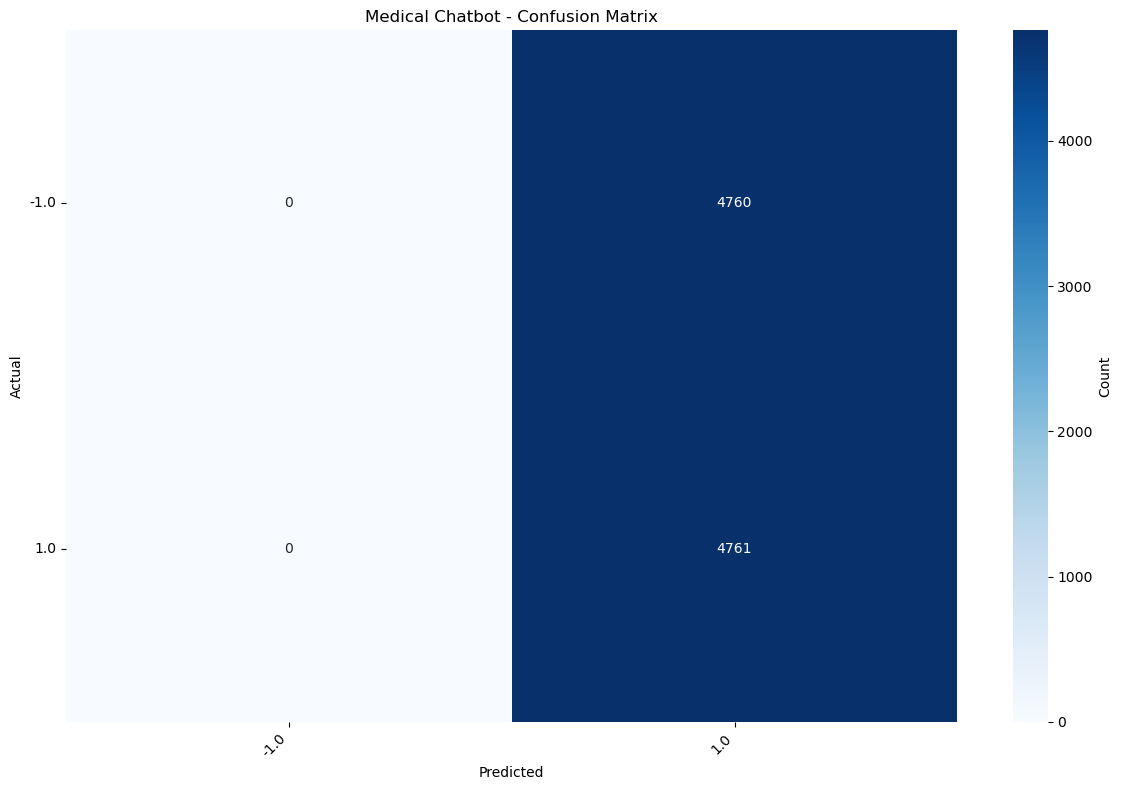


📊 Evaluating Response Quality...

📈 Response Quality Metrics:
Average BLEU score: 0.0076 (std: 0.0086)
Average ROUGE-1 F1: 0.1454 (std: 0.0758)
Average ROUGE-L F1: 0.0872 (std: 0.0390)

📊 Additional Statistics:
Total test samples: 9521
Number of unique true labels: 2
Number of unique predicted labels: 1
Valid BLEU scores calculated: 9521
Valid ROUGE scores calculated: 9521

✅ Evaluation results saved to 'evaluation_results.json'

📈 Prediction Distribution:
  1.0: 9521 predictions (100.0%)


In [12]:
# CELL 9: Evaluate model (accuracy, precision, recall, F1, confusion matrix, BLEU, ROUGE)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from rouge_score import rouge_scorer
import numpy as np

# Generate predictions on test set
y_true, y_pred = [], []
y_true_responses, y_pred_responses = [], []
scorer = rouge_scorer.RougeScorer(['rouge1', 'rougeL'], use_stemmer=True)
smoothie = SmoothingFunction().method4

model.eval()
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        _, preds = torch.max(outputs.logits, dim=1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

        # For BLEU/ROUGE: get ground truth and predicted responses
        for i in range(len(labels)):
            true_label = labels.cpu().numpy()[i]
            pred_label = preds.cpu().numpy()[i]
            true_intent = label_encoder.inverse_transform([true_label])[0]
            pred_intent = label_encoder.inverse_transform([pred_label])[0]
            
            # Check if responses exist for these intents
            true_response_rows = df[df['label'] == true_intent]['short_answer']
            pred_response_rows = df[df['label'] == pred_intent]['short_answer']
            
            if not true_response_rows.empty:
                true_response = true_response_rows.sample(n=1).values[0]
            else:
                true_response = f"No response for {true_intent}"
                
            if not pred_response_rows.empty:
                pred_response = pred_response_rows.sample(n=1).values[0]
            else:
                pred_response = f"No response for {pred_intent}"
                
            y_true_responses.append(str(true_response))
            y_pred_responses.append(str(pred_response))

# Standard metrics
accuracy = accuracy_score(y_true, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

# Convert label classes to strings for display
target_names = [str(class_name) for class_name in label_encoder.classes_]

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=target_names))

# Create confusion matrix with proper labels
plt.figure(figsize=(12, 8))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", 
            xticklabels=target_names, yticklabels=target_names, 
            cmap="Blues", cbar_kws={'label': 'Count'})
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Medical Chatbot - Confusion Matrix")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# BLEU and ROUGE evaluation
print("\n📊 Evaluating Response Quality...")
bleu_scores = []
rouge_1_scores = []
rouge_l_scores = []

for ref, pred in zip(y_true_responses, y_pred_responses):
    try:
        # Ensure we have valid strings
        ref_str = str(ref).strip()
        pred_str = str(pred).strip()
        
        if ref_str and pred_str:
            ref_tokens = nltk.word_tokenize(ref_str.lower())
            pred_tokens = nltk.word_tokenize(pred_str.lower())
            
            # Calculate BLEU score
            if len(pred_tokens) > 0:
                bleu = sentence_bleu([ref_tokens], pred_tokens, smoothing_function=smoothie)
                bleu_scores.append(bleu)
            
            # Calculate ROUGE scores
            scores = scorer.score(ref_str, pred_str)
            rouge_1_scores.append(scores['rouge1'].fmeasure)
            rouge_l_scores.append(scores['rougeL'].fmeasure)
    except Exception as e:
        print(f"⚠️ Error processing response pair: {e}")
        continue

# Print results
print(f"\n📈 Response Quality Metrics:")
print(f"Average BLEU score: {np.mean(bleu_scores):.4f} (std: {np.std(bleu_scores):.4f})")
print(f"Average ROUGE-1 F1: {np.mean(rouge_1_scores):.4f} (std: {np.std(rouge_1_scores):.4f})")
print(f"Average ROUGE-L F1: {np.mean(rouge_l_scores):.4f} (std: {np.std(rouge_l_scores):.4f})")

# Additional evaluation metrics
print(f"\n📊 Additional Statistics:")
print(f"Total test samples: {len(y_true)}")
print(f"Number of unique true labels: {len(set(y_true))}")
print(f"Number of unique predicted labels: {len(set(y_pred))}")
print(f"Valid BLEU scores calculated: {len(bleu_scores)}")
print(f"Valid ROUGE scores calculated: {len(rouge_1_scores)}")

# Save evaluation results
evaluation_results = {
    'accuracy': accuracy,
    'precision': precision,
    'recall': recall,
    'f1_score': f1,
    'bleu_mean': np.mean(bleu_scores) if bleu_scores else 0,
    'rouge1_mean': np.mean(rouge_1_scores) if rouge_1_scores else 0,
    'rougeL_mean': np.mean(rouge_l_scores) if rouge_l_scores else 0,
    'confusion_matrix': cm.tolist(),
    'target_names': target_names,
    'total_samples': len(y_true)
}

# Save results to file
import json
with open('evaluation_results.json', 'w') as f:
    json.dump(evaluation_results, f, indent=2)
print("\n✅ Evaluation results saved to 'evaluation_results.json'")

# Display class distribution
print(f"\n📈 Prediction Distribution:")
unique, counts = np.unique(y_pred, return_counts=True)
for label_id, count in zip(unique, counts):
    label_name = label_encoder.inverse_transform([label_id])[0]
    percentage = (count / len(y_pred)) * 100
    print(f"  {label_name}: {count} predictions ({percentage:.1f}%)")

In [13]:
# CELL 10: Inference function - Using LabelEncoder
model_path = "medical_models/bert_best_model.pt"
if os.path.exists(model_path):
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.to(device)
    print(f"✅ Loaded best model from {model_path}")
    
def predict_intent_and_response(
    text,
    model=model,
    tokenizer=tokenizer,
    label_encoder=label_encoder,
    df=df,
    device=device,
    min_conf=0.5
):
    encoding = tokenizer(
        text,
        truncation=True,
        padding='max_length',
        max_length=128,
        return_tensors='pt'
    )
    input_ids = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)

    model.eval()
    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        probs = torch.softmax(outputs.logits, dim=1)
        predicted_class = torch.argmax(probs).item()
        confidence = probs[0, predicted_class].item()
        
        # Convert back to original label using label_encoder
        original_label = label_encoder.inverse_transform([predicted_class])[0]

    if confidence < min_conf:
        return original_label, confidence, "I'm not confident about your prediction. Could you provide more context?"

    # Find responses based on original label
    response_rows = df[df['label'] == original_label]
    if not response_rows.empty:
        response = response_rows['short_answer'].sample(n=1).values[0]
    else:
        response = f"Sorry, I can't find a response for label {original_label}."
    
    return original_label, confidence, response

print("🤖 Classifier is ready! Type 'exit' to quit.")
while True:
    user_input = input("You: ")
    if user_input.strip().lower() == "exit":
        print("Classifier session ended.")
        break
    predicted_label, conf, response = predict_intent_and_response(user_input)
    print(f"Predicted Label: {predicted_label} (Confidence: {conf:.2f})")
    print(f"Response: {response}\n")


🤖 Classifier is ready! Type 'exit' to quit.


You:  is all vitamin d the same


Predicted Label: 1.0 (Confidence: 0.51)
Response: all of these are manifestations of scleroderma the bed sore is due to immobilization and this needs high care by disinfecting and cleaning or debridement try seeing an osteopath for treating the jaw and some other joint pains physiotherapy also can help



You:  can an antibiotic through an iv give you a rash a couple days later


Predicted Label: 1.0 (Confidence: 0.51)
Response: this is a sign of gut infection starting on antibiotics prebiotics and maintaining good hydration should help



You:  can an antibiotic through an iv give you a rash a couple days later


... (25 outputs left out)

You:  quit


Predicted Label: 1.0 (Confidence: 0.50)
Response: hi do have a read through this link it could help you with your problem <link> just copy link into google to the www to open and read good luck



You:  exit


Classifier session ended.
